# Assignment 3: A-OKVQA Results (M2 Draft and M3 Final)

This notebook reads the evaluated runs in `Assignment3/outputs` (7 configurations x seeds 42 to 46) and reports every metric as mean ± standard deviation over seeds. All models use the same frozen CLIP ViT-B/32 features (`features.py`), the same split (`splits.csv`) and the settings in `configs/a3.yaml`.

| Run | Uses | Fusion | Milestone |
|---|---|---|---|
| TextOnly | question, choices | none (modality A) | M2 |
| ImageOnly | image, choices | none (modality B) | M2 |
| LateFusion | image, question, choices | concatenation of global vectors + products | M2 |
| CrossAttention | image, question, choices | LateFusion + choice tokens attend to the 50 image tokens | M3 |
| LateFusionNoProduct | image, question, choices | concatenation only (ablation) | M3 |
| LateFusionFineTune | image, question, choices | LateFusion + last CLIP vision block trained (ablation) | M3 |
| CrossAttentionFineTune | image, question, choices | CrossAttention + last CLIP vision block trained (ablation) | M3 |

## 0. Setup

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from io import BytesIO

ROOT = Path.cwd().resolve()
if ROOT.name == "Assignment3":  # find the repository root
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "Assignment3"))
OUTPUTS = ROOT / "Assignment3" / "outputs"
FEATURES = ROOT / "data" / "aokvqa" / "features"
FIG_DIR = ROOT.parent / "latex" / "a3_m3_report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
MODELS = ["TextOnly", "ImageOnly", "LateFusion", "CrossAttention", "LateFusionNoProduct", "LateFusionFineTune", "CrossAttentionFineTune"]
LETTERS = "ABCD"

plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 12, "axes.labelsize": 12,
                     "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10})


def mean_sd(values, digits=4):
    """Format a list of numbers as 'mean ± sample SD'."""
    values = np.array(values, dtype=float)
    if len(values) == 1:
        return f"{values[0]:.{digits}f} (one seed)"
    return f"{values.mean():.{digits}f} ± {values.std(ddof=1):.{digits}f}"


def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150)

## 1. Saved runs

One row per run and seed. The notebook stops if a run and seed appear twice.

In [2]:
records, predictions = [], {}
for metrics_file in sorted(OUTPUTS.glob("*_seed*/metrics.json")):
    info = json.loads(metrics_file.read_text())
    key = (info["model"], info["seed"])
    if key in predictions:
        raise ValueError(f"two runs for {key}")
    predictions[key] = dict(np.load(metrics_file.parent / "test_predictions.npz"))
    history = pd.read_csv(metrics_file.parent / "history.csv")
    records.append({"model": info["model"], "seed": info["seed"], "folder": metrics_file.parent.name,
                    "commit": info["source_commit"][:7], "uncommitted": info["source_uncommitted"],
                    "gpu": info["gpu"], "parameters": info["parameters"], "trainable": info["trainable_parameters"],
                    "best_epoch": info["best_epoch"], "fit_seconds": info["fit_seconds"],
                    "epoch_seconds": history["seconds"].median(),
                    "val_accuracy": info["validation"]["accuracy"], "val_da": info["validation"]["da_score"],
                    "test_accuracy": info["test"]["accuracy"], "test_da": info["test"]["da_score"],
                    "shuffled_accuracy": info["test"]["shuffled_image_accuracy"],
                    "head_ms": info["test"]["head_ms_per_question"]})
runs = pd.DataFrame(records)
runs["order"] = [MODELS.index(m) for m in runs["model"]]
runs = runs.sort_values(["order", "seed"]).drop(columns="order").reset_index(drop=True)


def column(model, name):
    return runs.loc[runs["model"] == model].set_index("seed")[name]


display(pd.crosstab(runs["model"], runs["seed"]).reindex(MODELS))
pd.Series({"Runs": len(runs), "Commits": ", ".join(sorted(runs["commit"].unique())),
           "Flagged uncommitted": int(runs["uncommitted"].sum()), "GPU": ", ".join(sorted(runs["gpu"].unique()))},
          name="Value").to_frame()

seed,42,43,44,45,46
model,,,,,
TextOnly,1,1,1,1,1
ImageOnly,1,1,1,1,1
LateFusion,1,1,1,1,1
CrossAttention,1,1,1,1,1
LateFusionNoProduct,1,1,1,1,1
LateFusionFineTune,1,1,1,1,1
CrossAttentionFineTune,1,1,1,1,1


,Value
Runs,35
Commits,54fa0c8
Flagged uncommitted,35
GPU,NVIDIA A40


### Observation

All 7 configurations have the same 5 seeds, 35 runs in total, each on one NVIDIA A40. The runs record commit 54fa0c8 and are flagged as uncommitted, because the Assignment 3 training code was not committed yet when they ran.

## 2. Test questions and reference scores

The references need no training: chance, the text-only rules of the EDA, and zero-shot CLIP, which picks the choice whose text "question answer: choice" is closest to the image.

In [3]:
meta = pd.read_pickle(FEATURES / "meta.pkl")
image = torch.load(FEATURES / "image.pt")
text = torch.load(FEATURES / "text.pt")
test_rows = np.where(meta["split"] == "test")[0]
labels = meta["label"].values
for key, result in predictions.items():
    assert (result["rows"] == test_rows).all(), f"test rows differ for {key}"

# zero-shot CLIP: cosine between the image vector and each "question answer: choice" vector
v = torch.nn.functional.normalize(image["v"].float(), dim=-1)[meta["image_index"].values]
qc = torch.nn.functional.normalize(text["qc"].float(), dim=-1)
zero_shot = torch.einsum("nd,nkd->nk", v, qc).argmax(1).numpy()


def da_scores(rows, chosen):
    """A-OKVQA direct-answer score of the chosen text for each question."""
    out = []
    for row, choice in zip(rows, chosen):
        answer = meta["choices"].iloc[row][choice].lower().strip()
        given = [a.lower().strip() for a in meta["direct_answers"].iloc[row]]
        out.append(min(given.count(answer) / 3, 1.0))
    return np.array(out)


train_rows = np.where(meta["split"] == "train")[0]
answer_counts = pd.Series([meta["choices"].iloc[r][labels[r]] for r in train_rows]).value_counts()
prior = np.array([int(np.argmax([answer_counts.get(c, 0) for c in meta["choices"].iloc[r]])) for r in test_rows])

reference = pd.DataFrame({
    "Test accuracy": [0.25, (prior == labels[test_rows]).mean(), (zero_shot[test_rows] == labels[test_rows]).mean()],
    "Test DA score": [np.nan, da_scores(test_rows, prior).mean(), da_scores(test_rows, zero_shot[test_rows]).mean()],
}, index=pd.Index(["Chance", "Answer-text prior (train counts)", "Zero-shot CLIP"], name="Reference"))
reference.round(4)

/tmp/ipykernel_1892563/36257858.py:10: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  v = torch.nn.functional.normalize(image["v"].float(), dim=-1)[meta["image_index"].values]


,Test accuracy,Test DA score
Reference,,
Chance,0.2500,NaN
Answer-text prior (train counts),0.3118,0.2812
Zero-shot CLIP,0.5362,0.4378


### Observation

Without any training, zero-shot CLIP already gets 53.6% test accuracy and a DA score of 0.438. The answer-text prior from the EDA gets 31.2% and chance is 25%. So a large part of the task is matching the image with the right choice text, which CLIP was pretrained to do.

## 3. Main comparison (M2 and M3 models)

Mean ± SD over five seeds. The checkpoint is chosen by validation accuracy; the test split is used once per run.

In [4]:
def summary(models, columns):
    rows = []
    for model in models:
        part = runs[runs["model"] == model]
        row = {"Model": model, "Seeds": len(part)}
        row.update({label: mean_sd(part[name]) for label, name in columns.items()})
        rows.append(row)
    return pd.DataFrame(rows).set_index("Model")


MAIN = ["TextOnly", "ImageOnly", "LateFusion", "CrossAttention"]
summary(MAIN, {"Val accuracy": "val_accuracy", "Test accuracy": "test_accuracy", "Test DA score": "test_da"})

,Seeds,Val accuracy,Test accuracy,Test DA score
Model,,,,
TextOnly,5,0.4750 ± 0.0033,0.4334 ± 0.0102,0.3620 ± 0.0082
ImageOnly,5,0.5792 ± 0.0053,0.5722 ± 0.0100,0.4628 ± 0.0085
LateFusion,5,0.5868 ± 0.0079,0.5769 ± 0.0091,0.4703 ± 0.0079
CrossAttention,5,0.5842 ± 0.0053,0.5759 ± 0.0067,0.4695 ± 0.0054


In [5]:
runs.pivot(index="seed", columns="model", values="test_accuracy")[MAIN].round(4)

model,TextOnly,ImageOnly,LateFusion,CrossAttention
seed,,,,
42,0.4201,0.5546,0.5616,0.5712
43,0.4419,0.5764,0.5843,0.5677
44,0.4271,0.5773,0.5799,0.5834
45,0.4332,0.5738,0.5825,0.5817
46,0.4445,0.5790,0.5764,0.5755


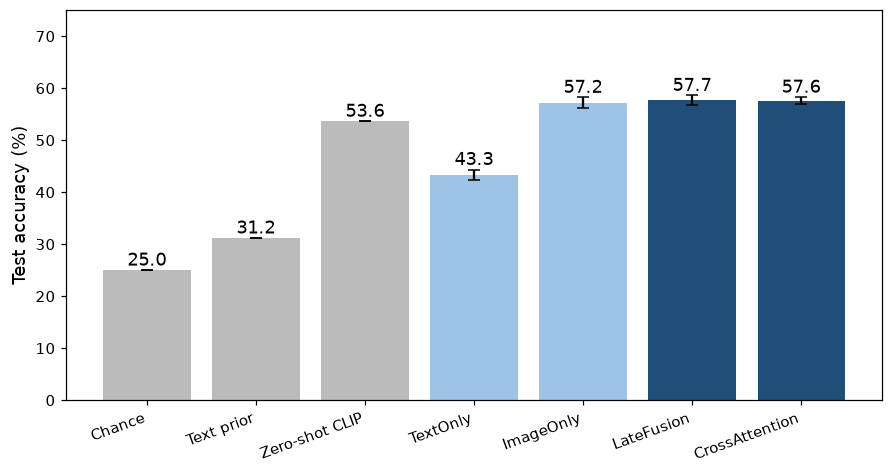

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
names = ["Chance", "Text prior", "Zero-shot CLIP"] + MAIN
means = [0.25, reference.iloc[1, 0], reference.iloc[2, 0]] + [column(m, "test_accuracy").mean() for m in MAIN]
sds = [0, 0, 0] + [column(m, "test_accuracy").std(ddof=1) for m in MAIN]
colors = ["#bbbbbb"] * 3 + ["#9dc3e6", "#9dc3e6", "#1f4e79", "#1f4e79"]
ax.bar(range(len(names)), [100 * m for m in means], yerr=[100 * s for s in sds], color=colors, capsize=4)
for i, m in enumerate(means):
    ax.annotate(f"{100 * m:.1f}", (i, 100 * m + 100 * sds[i]), xytext=(0, 3), textcoords="offset points", ha="center")
ax.set_xticks(range(len(names)), names, rotation=20, ha="right")
ax.set_ylabel("Test accuracy (%)")
ax.set_ylim(0, 75)
save(fig, "main_accuracy.png")
plt.show()

### Observation

Test accuracy: TextOnly 43.3 ± 1.0%, ImageOnly 57.2 ± 1.0%, LateFusion 57.7 ± 0.9%, CrossAttention 57.6 ± 0.7%. The DA score follows the same order (0.362, 0.463, 0.470, 0.470).

Adding the image to the text is a large gain: LateFusion is 14.4 points above TextOnly in all 5 seeds. Adding the question to the image is not: LateFusion is only 0.5 points above ImageOnly, smaller than the seed SD, and ImageOnly is even better in one seed. For these CLIP features the 4 choices plus the image carry almost all the information; the question mostly repeats what the choices already say.

The trained fusion models beat zero-shot CLIP by about 4 points. Test accuracy is about 1 point below validation accuracy for every model.

## 4. Learning curves

Solid: validation accuracy. Dashed: training accuracy. One colour per seed.

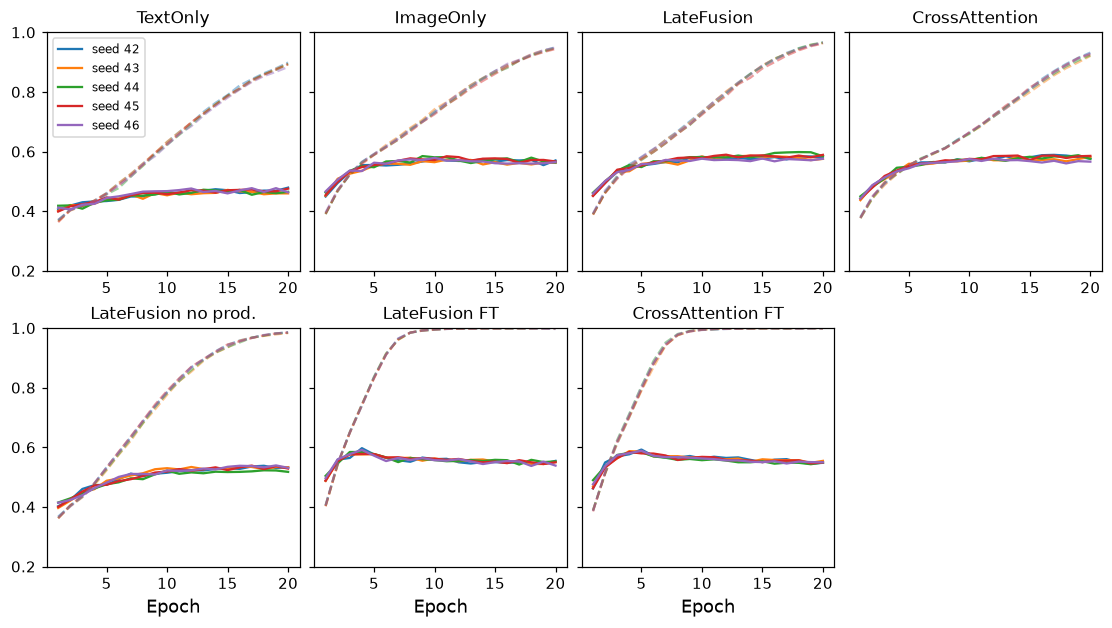

,Selected epoch (seeds 42-46)
TextOnly,"20, 15, 13, 20, 17"
ImageOnly,"14, 11, 9, 11, 10"
LateFusion,"19, 14, 18, 12, 15"
CrossAttention,"17, 14, 19, 14, 12"
LateFusionNoProduct,"18, 16, 18, 17, 19"
LateFusionFineTune,"4, 5, 3, 4, 4"
CrossAttentionFineTune,"5, 4, 5, 4, 5"


In [7]:
fig, axes = plt.subplots(2, 4, figsize=(10, 5.6), sharey=True, layout="constrained")
for ax, model in zip(axes.ravel(), MODELS):
    for _, run in runs[runs["model"] == model].iterrows():
        history = pd.read_csv(OUTPUTS / run["folder"] / "history.csv")
        line = ax.plot(history["epoch"], history["val_accuracy"], label=f"seed {run['seed']}")[0]
        ax.plot(history["epoch"], history["train_accuracy"], "--", color=line.get_color(), alpha=0.45)
    ax.set_title(model.replace("FineTune", " FT").replace("NoProduct", " no prod."), fontsize=11)
    ax.set_ylim(0.2, 1.0)
axes[0, 0].legend(fontsize=8)
axes[1, 3].axis("off")
for ax in axes[1]:
    ax.set_xlabel("Epoch")
save(fig, "learning_curves.png")
plt.show()
pd.Series({m: ", ".join(map(str, column(m, "best_epoch"))) for m in MODELS}, name="Selected epoch (seeds 42-46)").to_frame()

### Observation

All heads overfit: training accuracy goes above 0.9 for the fusion models while validation accuracy stays near 0.58. The frozen-feature models select epochs 9 to 20, so the 20-epoch budget is enough. The two fine-tuned models select epoch 3 to 5: with 7.1M extra trainable CLIP parameters they fit the training set faster and then overfit.

## 5. Does the model use the image?

Each fusion model is tested a second time with every test image replaced by the image of another test question (same seed for the shuffle). A model that ignores the image keeps its accuracy.

In [8]:
rows = []
for model in MODELS:
    part = runs[runs["model"] == model]
    rows.append({"Model": model, "Test accuracy": mean_sd(part["test_accuracy"]),
                 "With shuffled images": mean_sd(part["shuffled_accuracy"]),
                 "Drop (points)": f"{100 * (part['test_accuracy'] - part['shuffled_accuracy']).mean():.1f}"})
pd.DataFrame(rows).set_index("Model")

,Test accuracy,With shuffled images,Drop (points)
Model,,,
TextOnly,0.4334 ± 0.0102,0.4334 ± 0.0102,0.0
ImageOnly,0.5722 ± 0.0100,0.3219 ± 0.0046,25.0
LateFusion,0.5769 ± 0.0091,0.3432 ± 0.0034,23.4
CrossAttention,0.5759 ± 0.0067,0.3446 ± 0.0107,23.1
LateFusionNoProduct,0.5055 ± 0.0053,0.3544 ± 0.0017,15.1
LateFusionFineTune,0.5752 ± 0.0095,0.3144 ± 0.0112,26.1
CrossAttentionFineTune,0.5824 ± 0.0087,0.3228 ± 0.0129,26.0


### Observation

With the images shuffled, every model that uses the image falls to 31 to 35%, a drop of 23 to 26 points (15 points for LateFusionNoProduct). TextOnly does not change, as expected. So the image models really use the image, and a wrong image misleads them below what the text alone gives (43.3%).

## 6. Results by question type

A-OKVQA has no type field. We use the first words of the question, as planned in the proposal, and the dataset's `difficult` flag. Accuracy is averaged over seeds.

In [9]:
def question_type(question):
    words = question.lower().split()
    first_two = " ".join(words[:2])
    if first_two in ("how many",):
        return "how many"
    if first_two in ("what color", "what colour"):
        return "what color"
    if words[0] == "why":
        return "why"
    if first_two in ("what type", "what kind", "what sort"):
        return "what type / kind"
    if words[0] in ("what", "which"):
        return "what / which (other)"
    if words[0] in ("where", "who", "when"):
        return "where / who / when"
    return "other"


types = np.array([question_type(meta["question"].iloc[r]) for r in test_rows])
difficult = meta["difficult"].values[test_rows]


def accuracy_by(groups, model):
    correct = np.mean([predictions[(model, s)]["scores"].argmax(1) == labels[test_rows] for s in column(model, "test_accuracy").index], axis=0)
    return pd.Series(correct).groupby(groups).mean()


table = pd.DataFrame({m: accuracy_by(types, m) for m in MAIN})
table["Zero-shot CLIP"] = pd.Series(zero_shot[test_rows] == labels[test_rows]).groupby(types).mean()
table["Questions"] = pd.Series(types).value_counts()
table["Image gain (LateFusion - TextOnly)"] = table["LateFusion"] - table["TextOnly"]
display(table.sort_values("Questions", ascending=False).round(3))

flag = pd.DataFrame({m: accuracy_by(np.where(difficult, "difficult", "not difficult"), m) for m in MAIN})
flag["Questions"] = pd.Series(np.where(difficult, "difficult", "not difficult")).value_counts()
flag.round(3)

,TextOnly,ImageOnly,LateFusion,CrossAttention,Zero-shot CLIP,Questions,Image gain (LateFusion - TextOnly)
what / which (other),0.448,0.563,0.574,0.572,0.547,667,0.126
what type / kind,0.434,0.617,0.622,0.606,0.564,163,0.188
other,0.351,0.473,0.488,0.492,0.473,148,0.136
where / who / when,0.371,0.710,0.635,0.655,0.613,62,0.265
why,0.603,0.764,0.787,0.780,0.590,61,0.184
how many,0.312,0.444,0.412,0.438,0.188,32,0.100
what color,0.383,0.350,0.300,0.350,0.583,12,-0.083


,TextOnly,ImageOnly,LateFusion,CrossAttention,Questions
difficult,0.349,0.566,0.537,0.583,70
not difficult,0.439,0.573,0.580,0.575,1075


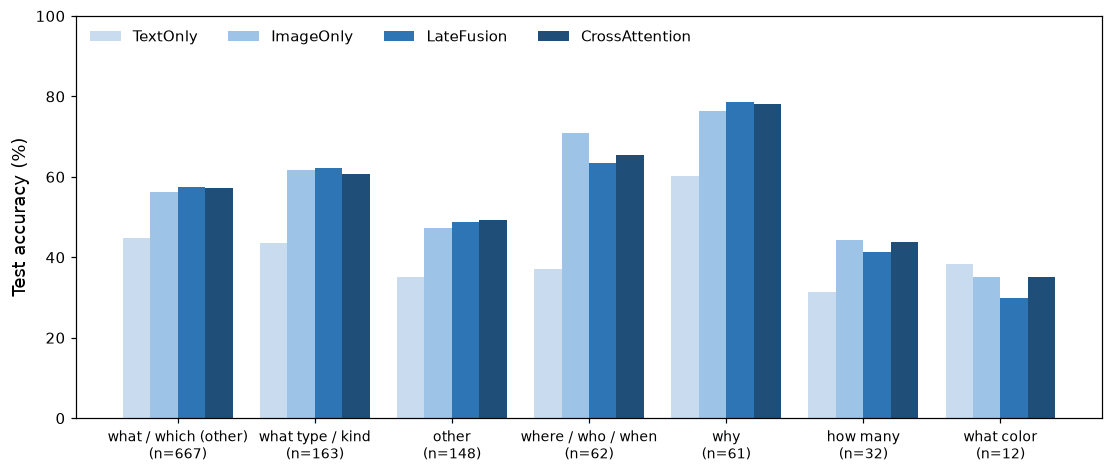

In [10]:
order = table.sort_values("Questions", ascending=False).index
fig, ax = plt.subplots(figsize=(10, 4.2), layout="constrained")
x = np.arange(len(order))
for k, (model, color) in enumerate([("TextOnly", "#c9dcef"), ("ImageOnly", "#9dc3e6"), ("LateFusion", "#2e75b6"), ("CrossAttention", "#1f4e79")]):
    ax.bar(x + (k - 1.5) * 0.2, 100 * table.loc[order, model], width=0.2, color=color, label=model)
ax.set_xticks(x, [f"{t}\n(n={table.loc[t, 'Questions']})" for t in order], fontsize=9)
ax.set_ylabel("Test accuracy (%)")
ax.legend(ncols=4, loc="upper left", frameon=False)
ax.set_ylim(0, 100)
save(fig, "by_type.png")
plt.show()

### Observation

The image helps most on where / who / when questions (+26.5 points, 62 questions), what type / kind (+18.8) and why (+18.4). For where / who / when, ImageOnly (71%) is even better than the fusion models (64 to 66%).

Two types stay hard. How many: 41 to 44% for the image models, because one global CLIP vector does not count objects. What color: only 12 questions, the fusion models get 30 to 35%, below TextOnly (38%) and far below zero-shot CLIP (58%); with so few questions this is 4 or 5 questions, but it suggests the trained head loses some colour information that CLIP has.

On the 70 difficult questions CrossAttention (58.3%) is above LateFusion (53.7%). This is the only place where token-level fusion looks better, but 70 questions are too few to conclude.

## 7. Support and conflict cases

Compare the text-only and late-fusion models on the same seed. Support: fusion right, text-only wrong (the image helped). Conflict: text-only right, fusion wrong (the image misled the model).

In [11]:
SEED = 42
text_right = predictions[("TextOnly", SEED)]["scores"].argmax(1) == labels[test_rows]
fusion_pred = predictions[("LateFusion", SEED)]["scores"].argmax(1)
fusion_right = fusion_pred == labels[test_rows]
display(pd.crosstab(pd.Series(text_right, name="TextOnly right"), pd.Series(fusion_right, name="LateFusion right")))

support_counts, conflict_counts = [], []
for s in column("LateFusion", "test_accuracy").index:
    t = predictions[("TextOnly", s)]["scores"].argmax(1) == labels[test_rows]
    f = predictions[("LateFusion", s)]["scores"].argmax(1) == labels[test_rows]
    support_counts.append(int((~t & f).sum()))
    conflict_counts.append(int((t & ~f).sum()))
print("support per seed:", support_counts, "| conflict per seed:", conflict_counts)

LateFusion right,False,True
TextOnly right,,
False,401,263
True,101,380


support per seed: [263, 269, 261, 282, 254] | conflict per seed: [101, 106, 86, 111, 103]


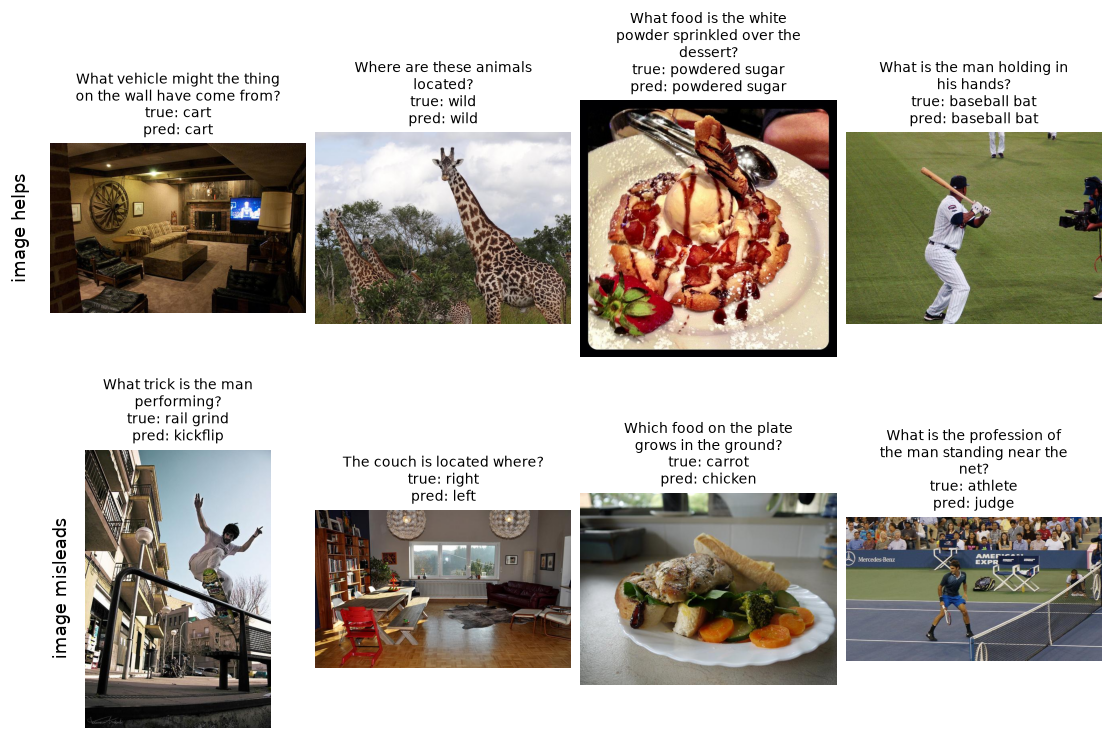

In [12]:
raw = pd.concat([pd.read_parquet(f) for f in sorted((ROOT / "data" / "aokvqa" / "data").glob("validation-*.parquet"))])
raw = raw.set_index("question_id")


def show(ax, row, chosen, title):
    item = raw.loc[meta["question_id"].iloc[row]]
    ax.imshow(Image.open(BytesIO(item["image"]["bytes"])).convert("RGB"))
    ax.axis("off")
    choices = meta["choices"].iloc[row]
    import textwrap
    q = textwrap.fill(meta["question"].iloc[row], 28)
    ax.set_title(f"{q}\ntrue: {choices[labels[row]]}\npred: {choices[chosen]}", fontsize=9)


rng = np.random.default_rng(SEED)
support = rng.choice(np.where(~text_right & fusion_right)[0], 4, replace=False)
conflict = rng.choice(np.where(text_right & ~fusion_right)[0], 4, replace=False)
fig, axes = plt.subplots(2, 4, figsize=(10, 6.6), layout="constrained")
for k, i in enumerate(support):
    show(axes[0, k], test_rows[i], fusion_pred[i], "support")
for k, i in enumerate(conflict):
    show(axes[1, k], test_rows[i], fusion_pred[i], "conflict")
axes[0, 0].text(-0.08, 0.5, "image helps", rotation=90, transform=axes[0, 0].transAxes, ha="right", va="center", fontsize=12)
axes[1, 0].text(-0.08, 0.5, "image misleads", rotation=90, transform=axes[1, 0].transAxes, ha="right", va="center", fontsize=12)
save(fig, "support_conflict.png")
plt.show()

### Observation

For seed 42, the image helps (LateFusion right, TextOnly wrong) on 263 questions and misleads (TextOnly right, LateFusion wrong) on 101. Over the 5 seeds support is 254 to 282 and conflict 86 to 111, so support is about 2.6 times more common.

Support cases are questions whose answer is an object or scene that is clearly visible (baseball bat, powdered sugar, wild animals). Conflict cases are questions where a visible object is not the answer: left / right (the global image vector has no position), a plausible but wrong object on the plate (chicken instead of carrot), or a person whose role needs reasoning (athlete vs judge).

## 8. Ablations

Each ablation changes one factor; seeds, split, features, optimizer and epochs stay fixed. Decision rule from the proposal: a difference counts only if the gap of the means is larger than the larger seed SD.

In [13]:
PAIRS = [("Fusion level", "LateFusion", "CrossAttention"),
         ("Fusion operation", "LateFusion", "LateFusionNoProduct"),
         ("Freeze vs fine-tune (late fusion)", "LateFusion", "LateFusionFineTune"),
         ("Freeze vs fine-tune (cross-attention)", "CrossAttention", "CrossAttentionFineTune"),
         ("Remove the image", "LateFusion", "TextOnly"),
         ("Remove the question", "LateFusion", "ImageOnly")]
rows = []
for label, base, other in PAIRS:
    a, b = column(base, "test_accuracy"), column(other, "test_accuracy")
    larger_sd = max(a.std(ddof=1), b.std(ddof=1))
    rows.append({"Ablation": label, "Base": base, "Base accuracy": mean_sd(a), "Changed": other,
                 "Changed accuracy": mean_sd(b), "Paired change (points)": f"{100 * (b - a).mean():+.1f} ± {100 * (b - a).std(ddof=1):.1f}",
                 "Seeds better": f"{((b - a) > 0).sum()}/5", "Beyond larger SD": abs(b.mean() - a.mean()) > larger_sd})
pd.DataFrame(rows).set_index("Ablation")

,Base,Base accuracy,Changed,Changed accuracy,Paired change (points),Seeds better,Beyond larger SD
Ablation,,,,,,,
Fusion level,LateFusion,0.5769 ± 0.0091,CrossAttention,0.5759 ± 0.0067,-0.1 ± 1.0,2/5,False
Fusion operation,LateFusion,0.5769 ± 0.0091,LateFusionNoProduct,0.5055 ± 0.0053,-7.1 ± 0.7,0/5,True
Freeze vs fine-tune (late fusion),LateFusion,0.5769 ± 0.0091,LateFusionFineTune,0.5752 ± 0.0095,-0.2 ± 1.7,2/5,False
Freeze vs fine-tune (cross-attention),CrossAttention,0.5759 ± 0.0067,CrossAttentionFineTune,0.5824 ± 0.0087,+0.6 ± 1.3,3/5,False
Remove the image,LateFusion,0.5769 ± 0.0091,TextOnly,0.4334 ± 0.0102,-14.4 ± 0.8,0/5,True
Remove the question,LateFusion,0.5769 ± 0.0091,ImageOnly,0.5722 ± 0.0100,-0.5 ± 0.5,1/5,False


### Observation

Decisions with the rule of the proposal (gap larger than the larger seed SD):

- Fusion operation: removing the product terms costs 7.1 ± 0.7 points, in 5 of 5 seeds. Supported, and the largest effect of any design choice. Plain concatenation cannot compare the image with each choice well.
- Fusion level: CrossAttention is 0.1 points below LateFusion. Not supported.
- Freeze vs fine-tune: training the last CLIP block changes accuracy by -0.2 (late fusion) and +0.6 (cross-attention) points. Not supported; it mostly makes the models overfit sooner.
- Remove the image: -14.4 points (supported). Remove the question: -0.5 points (not supported).

## 9. Error analysis

Errors of the best fusion model, grouped by question type and by agreement among the 10 direct answers (low agreement: the most common direct answer was given by at most 3 workers).

In [14]:
BEST = max(["LateFusion", "CrossAttention", "LateFusionFineTune", "CrossAttentionFineTune"], key=lambda m: column(m, "val_accuracy").mean())
print("Best fusion model by mean validation accuracy:", BEST)
agreement = np.array([pd.Series(meta["direct_answers"].iloc[r]).value_counts().iloc[0] for r in test_rows])
low = agreement <= 3
rows = []
for s in column(BEST, "test_accuracy").index:
    wrong = predictions[(BEST, s)]["scores"].argmax(1) != labels[test_rows]
    rows.append(pd.Series(types[wrong]).value_counts())
errors = pd.concat(rows, axis=1).fillna(0)
error_table = pd.DataFrame({"Errors per seed": errors.mean(1).round(1),
                            "Questions": pd.Series(types).value_counts(),
                            "Error rate": (errors.mean(1) / pd.Series(types).value_counts()).round(3)})
display(error_table.sort_values("Errors per seed", ascending=False))
acc_low = np.mean([(predictions[(BEST, s)]["scores"].argmax(1) == labels[test_rows])[low].mean() for s in column(BEST, "test_accuracy").index])
acc_high = np.mean([(predictions[(BEST, s)]["scores"].argmax(1) == labels[test_rows])[~low].mean() for s in column(BEST, "test_accuracy").index])
pd.Series({"Low-agreement questions": int(low.sum()), "Accuracy on them": round(acc_low, 4),
           "High-agreement questions": int((~low).sum()), "Accuracy on them ": round(acc_high, 4)}, name="Value").to_frame()

Best fusion model by mean validation accuracy: CrossAttentionFineTune


/tmp/ipykernel_1892563/1339634857.py:10: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  error_table = pd.DataFrame({"Errors per seed": errors.mean(1).round(1),
/tmp/ipykernel_1892563/1339634857.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  "Error rate": (errors.mean(1) / pd.Series(types).value_counts()).round(3)})


,Errors per seed,Questions,Error rate
what / which (other),286.6,667,0.430
other,72.2,148,0.488
what type / kind,60.2,163,0.369
where / who / when,20.4,62,0.329
how many,16.6,32,0.519
why,13.2,61,0.216
what color,9.0,12,0.750


,Value
Low-agreement questions,313.0000
Accuracy on them,0.5406
High-agreement questions,832.0000
Accuracy on them,0.5981


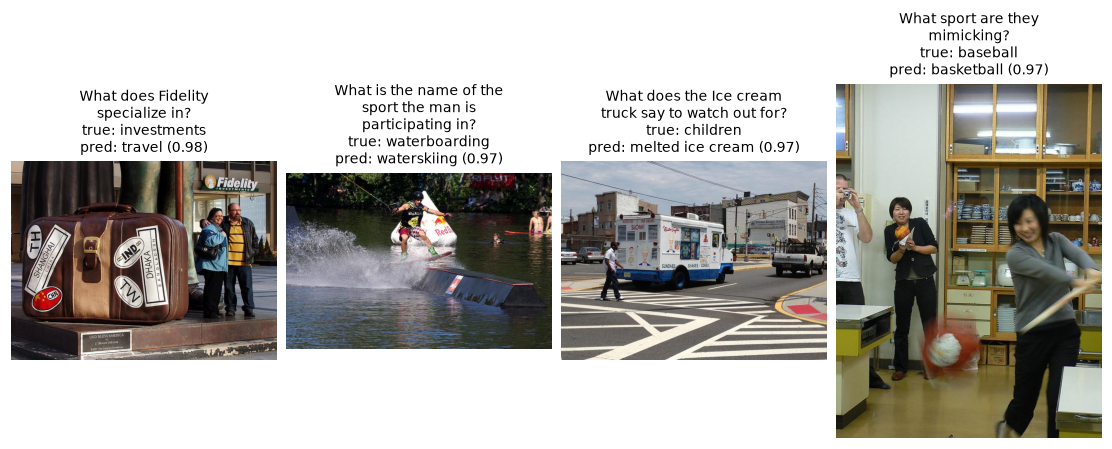

In [15]:
probabilities = torch.softmax(torch.tensor(predictions[(BEST, SEED)]["scores"]), 1).numpy()
chosen = probabilities.argmax(1)
wrong = np.where(chosen != labels[test_rows])[0]
worst = wrong[np.argsort(-probabilities[wrong].max(1))][:4]
fig, axes = plt.subplots(1, 4, figsize=(10, 4.6), layout="constrained")
for ax, i in zip(axes, worst):
    show(ax, test_rows[i], chosen[i], "")
    ax.set_title(ax.get_title() + f" ({probabilities[i].max():.2f})", fontsize=9)
save(fig, "confident_errors.png")
plt.show()

### Observation

The best fusion model by validation accuracy is CrossAttentionFineTune. Its error rate is highest on what color (75%, 12 questions), how many (52%) and the "other" openings (49%), and lowest on why questions (22%). Most errors are in the large what / which group (287 per seed) simply because it has 667 questions.

Accuracy is 54.1% on the 313 low-agreement questions and 59.8% on the 832 high-agreement ones, so part of the errors are on questions where the workers themselves disagree.

The four most confident errors (probability 0.97 to 0.98) follow the most visible thing in the image instead of the question: a suitcase with stickers gives "travel" for what Fidelity specializes in, a sign on an ice cream truck is not read ("children"), and two close sports are mixed up (waterboarding vs waterskiing, baseball vs basketball). These need reading text in the image or brand knowledge, which global CLIP features do not give.

## 10. Compute cost

One NVIDIA A40. Feature caching (`features.py`) is a one-time cost shared by all models: 99 s for the 17,661 images and 72 s for the 163,809 texts. Training time covers the 20 epochs with validation. Head time is milliseconds per test question with cached features.

In [16]:
rows = []
for model in MODELS:
    part = runs[runs["model"] == model]
    rows.append({"Model": model, "Parameters": int(part["parameters"].iloc[0]), "Trainable": int(part["trainable"].iloc[0]),
                 "Seconds per epoch": mean_sd(part["epoch_seconds"], 2), "Training minutes": mean_sd(part["fit_seconds"] / 60, 2),
                 "Head ms / question": mean_sd(part["head_ms"], 4), "Test accuracy": mean_sd(part["test_accuracy"])})
pd.DataFrame(rows).set_index("Model")

,Parameters,Trainable,Seconds per epoch,Training minutes,Head ms / question,Test accuracy
Model,,,,,,
TextOnly,787457,787457,0.29 ± 0.00,0.10 ± 0.00,0.0023 ± 0.0000,0.4334 ± 0.0102
ImageOnly,787457,787457,0.29 ± 0.01,0.10 ± 0.00,0.0023 ± 0.0000,0.5722 ± 0.0100
LateFusion,1311745,1311745,0.32 ± 0.01,0.11 ± 0.00,0.0027 ± 0.0000,0.5769 ± 0.0091
CrossAttention,3283969,3283969,2.74 ± 0.02,0.92 ± 0.01,0.0564 ± 0.0004,0.5759 ± 0.0067
LateFusionNoProduct,787457,787457,0.31 ± 0.01,0.11 ± 0.00,0.0023 ± 0.0000,0.5055 ± 0.0053
LateFusionFineTune,8794369,8794369,2.85 ± 0.01,0.95 ± 0.00,0.0530 ± 0.0004,0.5752 ± 0.0095
CrossAttentionFineTune,10766593,10766593,5.52 ± 0.03,1.84 ± 0.01,0.1069 ± 0.0005,0.5824 ± 0.0087


### Observation

Encoding with CLIP is the main cost and is paid once: 99 s for all images (5.6 ms per image) and 72 s for all 163,809 texts on one A40. After that, every head trains in 0.1 to 1.8 minutes and answers a test question in 0.002 to 0.11 ms. LateFusion has 1.3M trainable parameters; CrossAttention 3.3M; the fine-tuned versions add the 7.1M parameters of the last CLIP block. CrossAttention is about 9 times slower per epoch than LateFusion for the same accuracy, so LateFusion is the better trade-off.

## 11. Conclusion

- Modalities: the image is the key modality (+14.4 points over text only; shuffling images costs 23 to 26 points). The question adds little once the image and the choices are known (+0.5 points, not significant).
- Fusion: the product terms matter most (+7.1 points). Token-level cross-attention and fine-tuning the last CLIP block do not improve accuracy beyond seed noise.
- Best result: about 58% test accuracy, 4 points above zero-shot CLIP and 33 points above chance.
- Hard cases: counting, colour, left / right, and questions that need knowledge about what is visible.